# 🔬 Skin Undertone Classification — ConvNeXt + XGBoost

Pipeline hybrid untuk klasifikasi undertone (**cool / neutral / warm**) dari foto urat nadi pergelangan tangan:

| Tahap | Isi |
|---|---|
| 1. Pre-processing | EXIF-orientation fix → resize sisi pendek (aspect ratio tetap) → **Unsharp Mask (penajaman)**. **Tidak ada perubahan warna** (tanpa ColorJitter, grayscale, CLAHE, white-balance, histogram equalization). |
| 2. Augmentasi | Hanya **geometrik**: RandomResizedCrop (zoom), rotasi ±15°, flip horizontal/vertikal, sedikit perspektif. Diterapkan **hanya ke data train**. |
| 3. ConvNeXt-Tiny | Pretrained ImageNet, di-*fine-tune* singkat agar embedding peka terhadap rona urat nadi. |
| 4. Ekstraksi fitur | Embedding ConvNeXt 768-dim + **fitur warna terukur** (statistik Lab/HSV kulit & piksel urat). Train diekstrak dari beberapa *view* augmentasi → data XGBoost bertambah. |
| 5. XGBoost | Klasifikasi akhir dari fitur, early stopping pada valid. |
| 6. Evaluasi | Test set: ConvNeXt saja vs XGBoost vs Ensemble. |

> Catatan: `Normalize(mean, std)` ImageNet hanya menskalakan nilai tensor agar sesuai bobot pretrained — bukan mengubah warna gambar.

> **Kaggle**: aktifkan *Internet* (Settings → Internet on) agar bobot pretrained ConvNeXt bisa diunduh, dan pilih accelerator GPU.

In [1]:
# ========================================================
# 1. SETUP ENVIRONMENT & DEPENDENCIES
# ========================================================
import os
import sys
import json
import time
import copy
import math
import random
import warnings
import numpy as np
from PIL import Image, ImageFilter, ImageOps

import matplotlib
import matplotlib.colors
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import datasets, transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

try:
    import xgboost as xgb
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
    import xgboost as xgb

from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix as sk_confusion_matrix, classification_report)
from sklearn.utils.class_weight import compute_sample_weight

# Penanganan citra resolusi ekstrem
Image.MAX_IMAGE_PIXELS = None
warnings.filterwarnings("ignore", category=Image.DecompressionBombWarning)
warnings.filterwarnings("ignore", category=UserWarning)

print(f"📦 PyTorch     : {torch.__version__}")
print(f"📦 TorchVision : {torchvision.__version__}")
print(f"📦 XGBoost     : {xgb.__version__}")
print(f"📦 Pillow      : {Image.__version__}")
print(f"📦 NumPy       : {np.__version__}")

📦 PyTorch     : 2.11.0+cu128
📦 TorchVision : 0.26.0+cu128
📦 XGBoost     : 3.4.1
📦 Pillow      : 12.3.0
📦 NumPy       : 2.1.3


In [2]:
# ========================================================
# 2. KONFIGURASI GLOBAL & AUTO PATH DISCOVERY
# ========================================================
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

def auto_detect_dataset_dirs():
    candidates = [
        "/kaggle/input/datasets/sonymikio/skin-undertone",
        "/kaggle/input/skin-undertone-classification",
        "/kaggle/input/skin-undertone",
        "./",
        "../",
        r"C:\Users\Sonymikio\Downloads\archive"
    ]
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "train" in dirs and "valid" in dirs:
                print(f"🔍 Dataset otomatis ditemukan di Kaggle: {root}")
                return root

    for candidate in candidates:
        if os.path.exists(candidate) and os.path.exists(os.path.join(candidate, "train")):
            print(f"🔍 Dataset ditemukan di path: {candidate}")
            return candidate

    fallback = "/kaggle/input/datasets/sonymikio/skin-undertone"
    print(f"⚠️ Menggunakan fallback path: {fallback}")
    return fallback

BASE_DIR  = auto_detect_dataset_dirs()
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VALID_DIR = os.path.join(BASE_DIR, "valid")
TEST_DIR  = os.path.join(BASE_DIR, "test")

OUTPUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_PATH = os.path.join(OUTPUT_DIR, "skin_undertone_convnext.pth")
XGB_PATH   = os.path.join(OUTPUT_DIR, "skin_undertone_xgboost.json")

# ---------- Hyperparameter ----------
IMG_SIZE        = 224      # ConvNeXt butuh resolusi cukup (64px -> feature map hanya 2x2)
CACHE_SHORT     = 288      # sisi pendek gambar yang di-cache di RAM (sebelum crop)
BATCH_SIZE      = 16
NUM_EPOCHS      = 25       # fine-tuning ConvNeXt
PATIENCE        = 7        # early stopping
LR_BACKBONE     = 5e-5
LR_HEAD         = 1e-3
WEIGHT_DECAY    = 0.05
LABEL_SMOOTHING = 0.1
DROPOUT_RATE    = 0.3
N_AUG_VIEWS     = 6        # jumlah view augmentasi per gambar train untuk fitur XGBoost
USE_FINETUNE    = True     # False = ConvNeXt dibekukan (pure feature extractor)
CLASS_NAMES     = ["cool", "neutral", "warm"]

ON_KAGGLE   = os.path.exists("/kaggle")
NUM_WORKERS = 2 if ON_KAGGLE else 0   # 0 aman untuk Jupyter di Windows

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
print(f"🖥️  Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")

🔍 Dataset otomatis ditemukan di Kaggle: /kaggle/input/datasets/sonymikio/skin-undertone
🖥️  Device: cuda
   GPU: Tesla T4


In [3]:
# ========================================================
# 3. REGISTRY EXPERIMENT AUTO-LOG FUNCTION
# ========================================================
def auto_log_experiment(env_globals: dict, topic: str, model: str, objective: str, dataset: str, owner: str) -> None:
    expected_metrics = {
        "accuracy": ["accuracy", "acc", "acc_val", "accuracy_score"],
        "f1": ["f1", "f1_score", "f1_val"],
        "precision": ["precision", "prec_val"],
        "recall": ["recall", "rec_val"]
    }

    found_metrics = {}
    for metric_key, possible_vars in expected_metrics.items():
        for var_name in possible_vars:
            if var_name in env_globals:
                val = env_globals[var_name]
                if isinstance(val, (int, float)):
                    found_metrics[metric_key] = float(val)
                break

    if not found_metrics:
        print("PERINGATAN: Tidak ada variabel metrik numerik yang terdeteksi.")
        return

    metadata = {
        "topic": topic,
        "model": model,
        "objective": objective,
        "dataset": dataset,
        "owner": owner,
        "metrics": found_metrics
    }

    print("\n===REGISTRY_PAYLOAD_START===")
    print(json.dumps(metadata, indent=2))
    print("===REGISTRY_PAYLOAD_END===")

In [4]:
# ========================================================
# 4. LOAD DATASET (CACHE DI RAM) & CEK DATA LEAKAGE
# ========================================================
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def load_and_resize(path, short_side=CACHE_SHORT):
    """Buka gambar, perbaiki orientasi EXIF, konversi RGB, resize sisi pendek.
    Aspect ratio dipertahankan, warna tidak diubah."""
    img = Image.open(path)
    img = ImageOps.exif_transpose(img)
    img = img.convert("RGB")
    w, h = img.size
    scale = short_side / min(w, h)
    if scale < 1:
        img = img.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.BICUBIC)
    return img

def load_split(split_dir):
    images, labels, paths = [], [], []
    for label, cls in enumerate(CLASS_NAMES):
        cls_dir = os.path.join(split_dir, cls)
        if not os.path.isdir(cls_dir):
            print(f"⚠️ Folder kelas tidak ada: {cls_dir}")
            continue
        for fname in sorted(os.listdir(cls_dir)):
            if fname.lower().endswith(IMG_EXTS):
                p = os.path.join(cls_dir, fname)
                try:
                    images.append(load_and_resize(p))
                    labels.append(label)
                    paths.append(p)
                except Exception as e:
                    print(f"   ❌ Gagal membaca {p}: {e}")
    return images, np.array(labels), paths

t0 = time.time()
train_imgs, y_train, train_paths = load_split(TRAIN_DIR)
valid_imgs, y_valid, valid_paths = load_split(VALID_DIR)
test_imgs,  y_test,  test_paths  = load_split(TEST_DIR)
print(f"✅ Data dimuat dalam {time.time()-t0:.1f} detik")

for name, y in [("Train", y_train), ("Valid", y_valid), ("Test", y_test)]:
    counts = {CLASS_NAMES[i]: int((y == i).sum()) for i in range(len(CLASS_NAMES))}
    print(f"   {name:<5}: {len(y):>4} gambar  {counts}")

# Cek kebocoran: nama file asli (sebelum suffix Roboflow '.rf.xxx') tidak boleh muncul di 2 split
def base_name(p):
    return os.path.basename(p).split(".rf.")[0]

tr_b, va_b, te_b = (set(map(base_name, ps)) for ps in (train_paths, valid_paths, test_paths))
print(f"\n🔎 Overlap nama file  train∩valid: {len(tr_b & va_b)} | train∩test: {len(tr_b & te_b)} | valid∩test: {len(va_b & te_b)}")

✅ Data dimuat dalam 43.1 detik
   Train:  625 gambar  {'cool': 173, 'neutral': 255, 'warm': 197}
   Valid:  153 gambar  {'cool': 32, 'neutral': 64, 'warm': 57}
   Test :   79 gambar  {'cool': 13, 'neutral': 39, 'warm': 27}

🔎 Overlap nama file  train∩valid: 0 | train∩test: 0 | valid∩test: 0


In [5]:
# ========================================================
# 5. PRE-PROCESSING (PENAJAMAN) & AUGMENTASI (TANPA UBAH WARNA)
# ========================================================
class SkinSharpenTransform:
    """
    Unsharp Mask: mempertegas tepi urat nadi.
    Hanya kontras lokal di sekitar tepi yang naik; rona (hue) kulit/urat tetap.
    """
    def __init__(self, radius: float = 2, percent: int = 120, threshold: int = 3):
        self.radius = radius
        self.percent = percent
        self.threshold = threshold

    def __call__(self, img: Image.Image) -> Image.Image:
        if not isinstance(img, Image.Image):
            img = transforms.functional.to_pil_image(img)
        return img.filter(ImageFilter.UnsharpMask(radius=self.radius,
                                                  percent=self.percent,
                                                  threshold=self.threshold))

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

sharpen = SkinSharpenTransform(radius=2, percent=120, threshold=3)

# Augmentasi HANYA geometrik -> warna asli tetap utuh
# fill=0 pada rotasi/perspektif hanya mengisi sudut kosong, tidak mengubah piksel kulit
geo_augment = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.75, 1.333),
                                 interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomApply([transforms.RandomRotation(degrees=15)], p=0.7),
    transforms.RandomPerspective(distortion_scale=0.15, p=0.3),
])

eval_geometry = transforms.Compose([
    transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(IMG_SIZE),
])

to_tensor_norm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Urutan: geometri -> penajaman (pada resolusi akhir) -> tensor
train_transforms = transforms.Compose([geo_augment, sharpen, to_tensor_norm])
eval_transforms  = transforms.Compose([eval_geometry, sharpen, to_tensor_norm])

class CachedImageDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        return self.transform(self.images[idx]), int(self.labels[idx])

print("✅ Pipeline penajaman & augmentasi geometrik siap (tanpa manipulasi warna).")

✅ Pipeline penajaman & augmentasi geometrik siap (tanpa manipulasi warna).


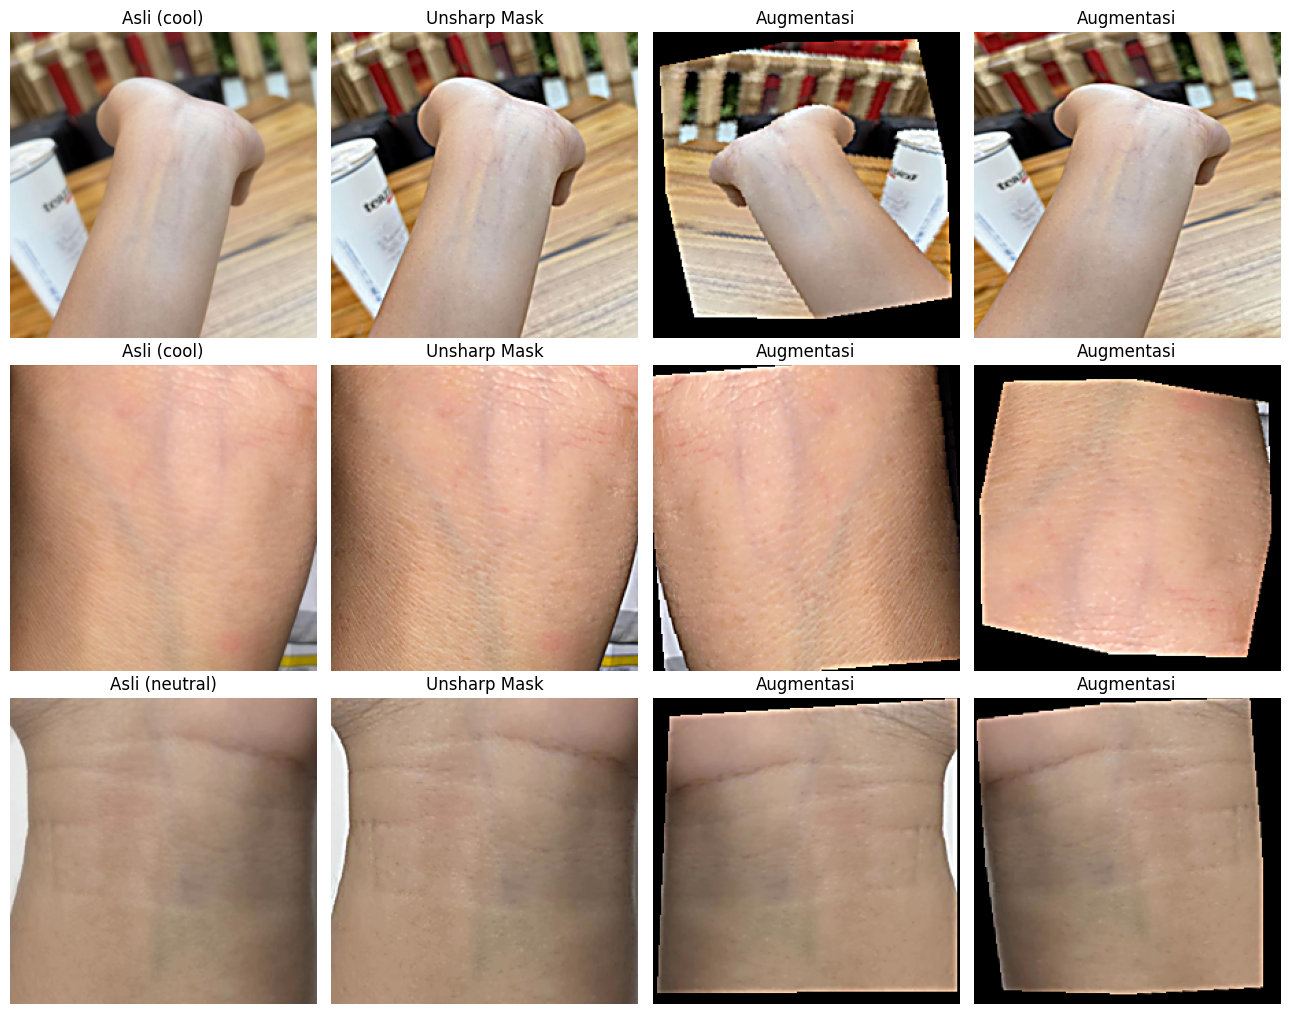

In [6]:
# ========================================================
# 6. VISUALISASI: ASLI vs DITAJAMKAN vs AUGMENTASI
# ========================================================
def show_preprocessing_examples(n=3):
    idxs = random.sample(range(len(train_imgs)), k=min(n, len(train_imgs)))
    fig, axes = plt.subplots(len(idxs), 4, figsize=(13, 3.4 * len(idxs)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        base = eval_geometry(train_imgs[i])
        axes[r, 0].imshow(base); axes[r, 0].set_title(f"Asli ({CLASS_NAMES[y_train[i]]})")
        axes[r, 1].imshow(sharpen(base)); axes[r, 1].set_title("Unsharp Mask")
        for c in (2, 3):
            axes[r, c].imshow(sharpen(geo_augment(train_imgs[i]))); axes[r, c].set_title("Augmentasi")
        for a in axes[r]:
            a.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "preprocessing_examples.png"), dpi=110)
    plt.show()

show_preprocessing_examples()

In [7]:
# ========================================================
# 7. FITUR WARNA TERUKUR (MEMBACA warna, tidak mengubahnya)
# ========================================================
def rgb_to_lab(rgb):
    """rgb: float array [0,1] (..., 3) sRGB -> CIELab (D65)."""
    rgb = np.where(rgb > 0.04045, ((rgb + 0.055) / 1.055) ** 2.4, rgb / 12.92)
    M = np.array([[0.4124564, 0.3575761, 0.1804375],
                  [0.2126729, 0.7151522, 0.0721750],
                  [0.0193339, 0.1191920, 0.9503041]])
    xyz = rgb @ M.T
    xyz = xyz / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    L = 116 * f[..., 1] - 16
    a = 500 * (f[..., 0] - f[..., 1])
    b = 200 * (f[..., 1] - f[..., 2])
    return np.stack([L, a, b], axis=-1)

def color_features(img: Image.Image) -> np.ndarray:
    """
    Statistik warna dari area tengah (kulit pergelangan) + piksel tergelap (kandidat urat nadi).
    Undertone ditentukan oleh rona urat (biru/ungu vs hijau) relatif terhadap kulit.
    """
    arr = np.asarray(img.resize((128, 128), Image.BILINEAR), dtype=np.float32) / 255.0
    h, w, _ = arr.shape
    center = arr[h // 6: h - h // 6, w // 6: w - w // 6].reshape(-1, 3)
    # Abaikan piksel hitam murni (sudut kosong akibat rotasi/perspektif)
    valid = center.sum(axis=1) > 0.03
    if valid.sum() > 50:
        center = center[valid]
    lab = rgb_to_lab(center)
    hsv = matplotlib.colors.rgb_to_hsv(center)

    feats = []
    for ch in (lab[:, 0], lab[:, 1], lab[:, 2], hsv[:, 1], hsv[:, 2]):
        feats += [ch.mean(), ch.std(), *np.percentile(ch, [10, 50, 90])]
    # Hue sebagai sudut (sin/cos)
    hue = hsv[:, 0] * 2 * np.pi
    feats += [np.sin(hue).mean(), np.cos(hue).mean()]
    # Rasio kanal RGB
    r, g, b = center[:, 0], center[:, 1], center[:, 2]
    feats += [(r - g).mean(), (b - g).mean(), (r - b).mean()]

    # Piksel urat: 12% piksel paling gelap (L rendah) dibanding median kulit
    L = lab[:, 0]
    vein = lab[L <= np.percentile(L, 12)]
    skin_med = np.median(lab, axis=0)
    vein_med = np.median(vein, axis=0) if len(vein) else skin_med
    diff = vein_med - skin_med
    feats += [*vein_med, *diff, math.atan2(diff[2], diff[1])]   # sudut hue urat relatif kulit
    return np.array(feats, dtype=np.float32)

COLOR_FEAT_DIM = len(color_features(train_imgs[0]))
print(f"🎨 Jumlah fitur warna: {COLOR_FEAT_DIM}")

🎨 Jumlah fitur warna: 37


In [8]:
# ========================================================
# 8. ARSITEKTUR CONVNEXT-TINY (PRETRAINED IMAGENET)
# ========================================================
class ConvNeXtUndertone(nn.Module):
    def __init__(self, num_classes=3, dropout_rate=0.3, pretrained=True):
        super().__init__()
        weights = None
        if pretrained:
            try:
                weights = ConvNeXt_Tiny_Weights.IMAGENET1K_V1
                backbone = convnext_tiny(weights=weights)
                print("✅ Bobot pretrained ImageNet berhasil dimuat")
            except Exception as e:
                print(f"⚠️ Gagal mengunduh bobot pretrained ({e}).\n"
                      f"   Aktifkan Internet di Kaggle. Melanjutkan dengan bobot acak.")
                backbone = convnext_tiny(weights=None)
        else:
            backbone = convnext_tiny(weights=None)

        self.features = backbone.features
        self.avgpool  = backbone.avgpool
        self.norm     = backbone.classifier[0]   # LayerNorm2d
        self.flatten  = nn.Flatten(1)
        self.embed_dim = backbone.classifier[2].in_features  # 768
        self.head = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(self.embed_dim, num_classes),
        )

    def embed(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = self.norm(x)
        return self.flatten(x)

    def forward(self, x):
        return self.head(self.embed(x))

model = ConvNeXtUndertone(num_classes=len(CLASS_NAMES), dropout_rate=DROPOUT_RATE).to(device)
params_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"🏗️  Model Siap: ConvNeXt-Tiny ({params_count:,} parameters, embedding {model.embed_dim}-dim)")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 200MB/s] 


✅ Bobot pretrained ImageNet berhasil dimuat
🏗️  Model Siap: ConvNeXt-Tiny (27,822,435 parameters, embedding 768-dim)


In [9]:
# ========================================================
# 9. FINE-TUNING CONVNEXT (TRAIN + VALIDASI)
# ========================================================
def make_loader(images, labels, transform, shuffle):
    return DataLoader(CachedImageDataset(images, labels, transform),
                      batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

def run_epoch(loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                outputs = model(inputs)
                loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * inputs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += inputs.size(0)
    return total_loss / total, correct / total * 100

def train_model():
    if len(train_imgs) == 0 or len(valid_imgs) == 0:
        print("❌ Dataset tidak ditemukan. Pastikan direktori dataset benar.")
        return None

    train_loader = make_loader(train_imgs, y_train, train_transforms, shuffle=True)
    valid_loader = make_loader(valid_imgs, y_valid, eval_transforms, shuffle=False)

    # Class weights untuk ketimpangan kelas
    class_counts = np.bincount(y_train, minlength=len(CLASS_NAMES))
    class_weights = len(y_train) / (len(CLASS_NAMES) * np.maximum(class_counts, 1))
    print("📊 Distribusi Sampel Train:")
    for name, cnt, w in zip(CLASS_NAMES, class_counts, class_weights):
        print(f"   - {name:<8}: {cnt:>3} gambar (Bobot Loss: {w:.3f})")

    criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device),
                                    label_smoothing=LABEL_SMOOTHING)
    optimizer = optim.AdamW([
        {"params": model.features.parameters(), "lr": LR_BACKBONE},
        {"params": list(model.norm.parameters()) + list(model.head.parameters()), "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_val_loss, bad_epochs = -1.0, float("inf"), 0
    start_time = time.time()
    print(f"\n🚀 Fine-tuning ConvNeXt ({NUM_EPOCHS} epoch maks, patience {PATIENCE})\n" + "=" * 60)

    for epoch in range(NUM_EPOCHS):
        tr_loss, tr_acc = run_epoch(train_loader, criterion, optimizer, scaler)
        va_loss, va_acc = run_epoch(valid_loader, criterion)
        scheduler.step()

        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)
        print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS:02d}] | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.2f}% "
              f"| Val Loss: {va_loss:.4f} Acc: {va_acc:.2f}%")

        # Simpan jika akurasi valid naik (tie-break: loss lebih rendah)
        if va_acc > best_val_acc or (va_acc == best_val_acc and va_loss < best_val_loss):
            best_val_acc, best_val_loss, bad_epochs = va_acc, va_loss, 0
            torch.save({"epoch": epoch + 1, "model_state_dict": model.state_dict(),
                        "val_acc": best_val_acc, "history": history,
                        "class_names": CLASS_NAMES, "img_size": IMG_SIZE}, MODEL_PATH)
            print(f"   ⭐ Best Model Disimpan! (Val Acc: {best_val_acc:.2f}%)")
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f"⏹️  Early stopping di epoch {epoch+1}")
                break

    print(f"\n🏁 Selesai dalam {time.time()-start_time:.1f} detik. Val Acc Terbaik: {best_val_acc:.2f}%")
    checkpoint = torch.load(MODEL_PATH, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    return history

if USE_FINETUNE:
    history = train_model()
else:
    history = None
    print("ℹ️ Fine-tuning dilewati: ConvNeXt dipakai sebagai feature extractor beku.")

📊 Distribusi Sampel Train:
   - cool    : 173 gambar (Bobot Loss: 1.204)
   - neutral : 255 gambar (Bobot Loss: 0.817)
   - warm    : 197 gambar (Bobot Loss: 1.058)

🚀 Fine-tuning ConvNeXt (25 epoch maks, patience 7)


/tmp/ipykernel_23/93371781.py:51: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


Epoch [01/25] | Train Loss: 1.1072 Acc: 39.52% | Val Loss: 1.0601 Acc: 42.48%
   ⭐ Best Model Disimpan! (Val Acc: 42.48%)
Epoch [02/25] | Train Loss: 1.0295 Acc: 44.48% | Val Loss: 1.0868 Acc: 45.10%
   ⭐ Best Model Disimpan! (Val Acc: 45.10%)
Epoch [03/25] | Train Loss: 0.9275 Acc: 57.60% | Val Loss: 1.0407 Acc: 47.06%
   ⭐ Best Model Disimpan! (Val Acc: 47.06%)
Epoch [04/25] | Train Loss: 0.8016 Acc: 67.68% | Val Loss: 0.9996 Acc: 54.25%
   ⭐ Best Model Disimpan! (Val Acc: 54.25%)
Epoch [05/25] | Train Loss: 0.7515 Acc: 71.20% | Val Loss: 1.1730 Acc: 45.75%
Epoch [06/25] | Train Loss: 0.6582 Acc: 79.68% | Val Loss: 1.0206 Acc: 54.90%
   ⭐ Best Model Disimpan! (Val Acc: 54.90%)
Epoch [07/25] | Train Loss: 0.5628 Acc: 85.92% | Val Loss: 1.0884 Acc: 53.59%
Epoch [08/25] | Train Loss: 0.5421 Acc: 86.08% | Val Loss: 1.1062 Acc: 57.52%
   ⭐ Best Model Disimpan! (Val Acc: 57.52%)
Epoch [09/25] | Train Loss: 0.4992 Acc: 91.20% | Val Loss: 1.1494 Acc: 57.52%
Epoch [10/25] | Train Loss: 0.4898

In [10]:
# ========================================================
# 10. EKSTRAKSI FITUR: EMBEDDING CONVNEXT + FITUR WARNA
# ========================================================
@torch.no_grad()
def embed_batch(pil_list):
    x = torch.stack([to_tensor_norm(sharpen(im)) for im in pil_list]).to(device)
    with torch.autocast(device_type=device.type, enabled=USE_AMP):
        emb = model.embed(x)
        logits = model.head(emb)
    return emb.float().cpu().numpy(), torch.softmax(logits.float(), 1).cpu().numpy()

def extract_features(images, labels, n_views=0, tta=True):
    """
    n_views = 0 -> 1 view bersih (eval). n_views > 0 -> tambah n_views view augmentasi (khusus train).
    tta=True    -> view bersih dirata-rata dengan versi flip horizontal.
    Return: X (embedding + fitur warna), y, probabilitas head ConvNeXt (view bersih).
    """
    model.eval()
    X, Y, P = [], [], []
    for start in range(0, len(images), BATCH_SIZE):
        batch = images[start:start + BATCH_SIZE]
        lab = labels[start:start + BATCH_SIZE]

        clean = [eval_geometry(im) for im in batch]
        emb, prob = embed_batch(clean)
        if tta:
            emb_f, prob_f = embed_batch([ImageOps.mirror(im) for im in clean])
            emb, prob = (emb + emb_f) / 2, (prob + prob_f) / 2
        col = np.stack([color_features(im) for im in clean])
        X.append(np.hstack([emb, col])); Y.append(lab); P.append(prob)

        for _ in range(n_views):
            views = [geo_augment(im) for im in batch]
            emb_v, _ = embed_batch(views)
            col_v = np.stack([color_features(im) for im in views])
            X.append(np.hstack([emb_v, col_v])); Y.append(lab)
    return np.vstack(X), np.concatenate(Y), np.vstack(P)

t0 = time.time()
set_seed(SEED)
X_train, Y_train_xgb, _          = extract_features(train_imgs, y_train, n_views=N_AUG_VIEWS)
X_valid, Y_valid_xgb, P_valid_cn = extract_features(valid_imgs, y_valid)
X_test,  Y_test_xgb,  P_test_cn  = extract_features(test_imgs,  y_test)
print(f"✅ Fitur diekstrak dalam {time.time()-t0:.1f} detik")
print(f"   X_train: {X_train.shape} (asli {len(train_imgs)} × {N_AUG_VIEWS+1} view)")
print(f"   X_valid: {X_valid.shape} | X_test: {X_test.shape}")

✅ Fitur diekstrak dalam 71.7 detik
   X_train: (4375, 805) (asli 625 × 7 view)
   X_valid: (153, 805) | X_test: (79, 805)


In [11]:
# ========================================================
# 11. TRAINING XGBOOST
# ========================================================
xgb_device = "cuda" if torch.cuda.is_available() else "cpu"
XGB_V2 = int(xgb.__version__.split(".")[0]) >= 2
gpu_kwargs = ({"tree_method": "hist", "device": xgb_device} if XGB_V2
              else {"tree_method": "gpu_hist" if xgb_device == "cuda" else "hist"})

xgb_clf = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=len(CLASS_NAMES),
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.4,
    colsample_bylevel=0.8,
    reg_lambda=2.0,
    reg_alpha=0.1,
    gamma=0.1,
    **gpu_kwargs,
    eval_metric="mlogloss",
    early_stopping_rounds=100,
    random_state=SEED,
)

sample_w = compute_sample_weight("balanced", Y_train_xgb)
t0 = time.time()
xgb_clf.fit(X_train, Y_train_xgb, sample_weight=sample_w,
            eval_set=[(X_train, Y_train_xgb), (X_valid, Y_valid_xgb)], verbose=200)
print(f"✅ XGBoost selesai dalam {time.time()-t0:.1f} detik | best iteration: {xgb_clf.best_iteration}")

P_valid_xgb = xgb_clf.predict_proba(X_valid)
print(f"   Val Acc XGBoost : {accuracy_score(y_valid, P_valid_xgb.argmax(1))*100:.2f}%")
print(f"   Val Acc ConvNeXt: {accuracy_score(y_valid, P_valid_cn.argmax(1))*100:.2f}%")

# Bobot ensemble dipilih di VALID (bukan test) supaya tidak bocor
best_w, best_acc = 1.0, -1
for w in np.linspace(0, 1, 11):
    acc_w = accuracy_score(y_valid, (w * P_valid_xgb + (1 - w) * P_valid_cn).argmax(1))
    if acc_w > best_acc:
        best_w, best_acc = w, acc_w
print(f"   Bobot ensemble terbaik (valid): XGB={best_w:.1f}, ConvNeXt={1-best_w:.1f} -> {best_acc*100:.2f}%")

xgb_clf.save_model(XGB_PATH)
print(f"💾 Model XGBoost disimpan: {XGB_PATH}")

[0]	validation_0-mlogloss:1.07553	validation_1-mlogloss:1.08932
[191]	validation_0-mlogloss:0.08870	validation_1-mlogloss:0.93751
✅ XGBoost selesai dalam 2.9 detik | best iteration: 91
   Val Acc XGBoost : 58.82%
   Val Acc ConvNeXt: 60.13%
   Bobot ensemble terbaik (valid): XGB=0.5, ConvNeXt=0.5 -> 61.44%
💾 Model XGBoost disimpan: /kaggle/working/skin_undertone_xgboost.json


In [12]:
# ========================================================
# 12. EVALUASI TEST SET & PERHITUNGAN METRIK
# ========================================================
def report(name, y_true, y_pred):
    acc_ = accuracy_score(y_true, y_pred) * 100
    prec_ = precision_score(y_true, y_pred, average="macro", zero_division=0) * 100
    rec_ = recall_score(y_true, y_pred, average="macro", zero_division=0) * 100
    f1_ = f1_score(y_true, y_pred, average="macro", zero_division=0) * 100
    print(f"\n{'='*55}\n📋 {name}\n{'='*55}")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
    print(f"🎯 Accuracy {acc_:.2f}% | Macro P {prec_:.2f}% | Macro R {rec_:.2f}% | Macro F1 {f1_:.2f}%")
    return {"accuracy": acc_, "macro_precision": prec_, "macro_recall": rec_, "macro_f1": f1_,
            "confusion_matrix": sk_confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES))).tolist()}

P_test_xgb = xgb_clf.predict_proba(X_test)
P_test_ens = best_w * P_test_xgb + (1 - best_w) * P_test_cn

results = {
    "ConvNeXt (head)":         report("ConvNeXt (head saja)", y_test, P_test_cn.argmax(1)),
    "ConvNeXt + XGBoost":      report("ConvNeXt features + XGBoost", y_test, P_test_xgb.argmax(1)),
    "Ensemble":                report(f"Ensemble (XGB {best_w:.1f} / ConvNeXt {1-best_w:.1f})", y_test, P_test_ens.argmax(1)),
}

print("\n📊 Ringkasan Test Set")
print(f"{'Model':<22}{'Acc':>8}{'F1':>8}")
for k, v in results.items():
    print(f"{k:<22}{v['accuracy']:>7.2f}%{v['macro_f1']:>7.2f}%")

final_metrics = results["ConvNeXt + XGBoost"]


📋 ConvNeXt (head saja)
              precision    recall  f1-score   support

        cool     0.5625    0.6923    0.6207        13
     neutral     0.6923    0.6923    0.6923        39
        warm     0.6667    0.5926    0.6275        27

    accuracy                         0.6582        79
   macro avg     0.6405    0.6591    0.6468        79
weighted avg     0.6622    0.6582    0.6584        79

🎯 Accuracy 65.82% | Macro P 64.05% | Macro R 65.91% | Macro F1 64.68%

📋 ConvNeXt features + XGBoost
              precision    recall  f1-score   support

        cool     0.4737    0.6923    0.5625        13
     neutral     0.6757    0.6410    0.6579        39
        warm     0.6522    0.5556    0.6000        27

    accuracy                         0.6203        79
   macro avg     0.6005    0.6296    0.6068        79
weighted avg     0.6344    0.6203    0.6224        79

🎯 Accuracy 62.03% | Macro P 60.05% | Macro R 62.96% | Macro F1 60.68%

📋 Ensemble (XGB 0.5 / ConvNeXt 0.5)
      

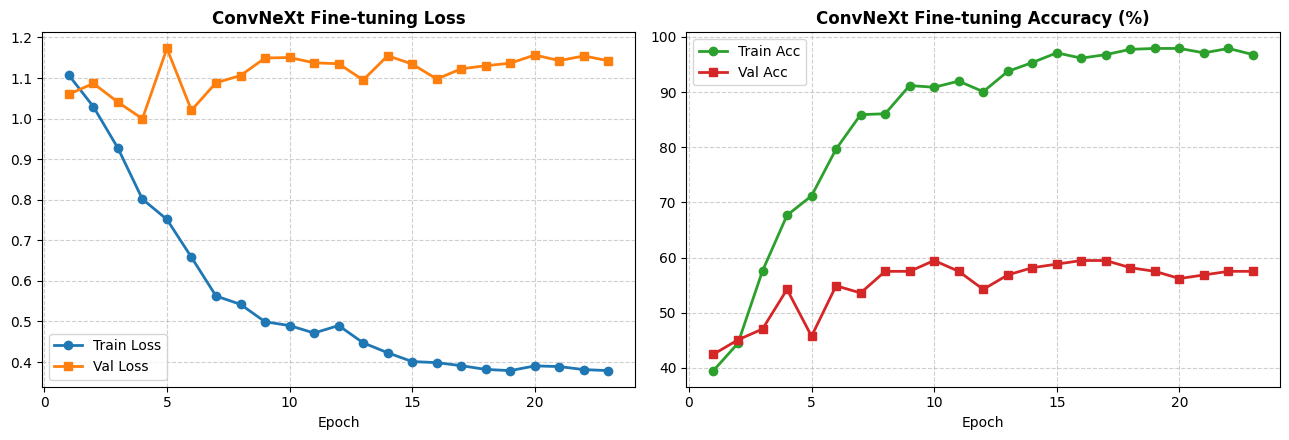

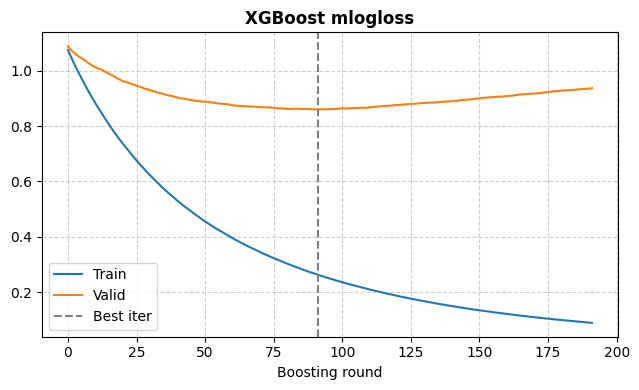

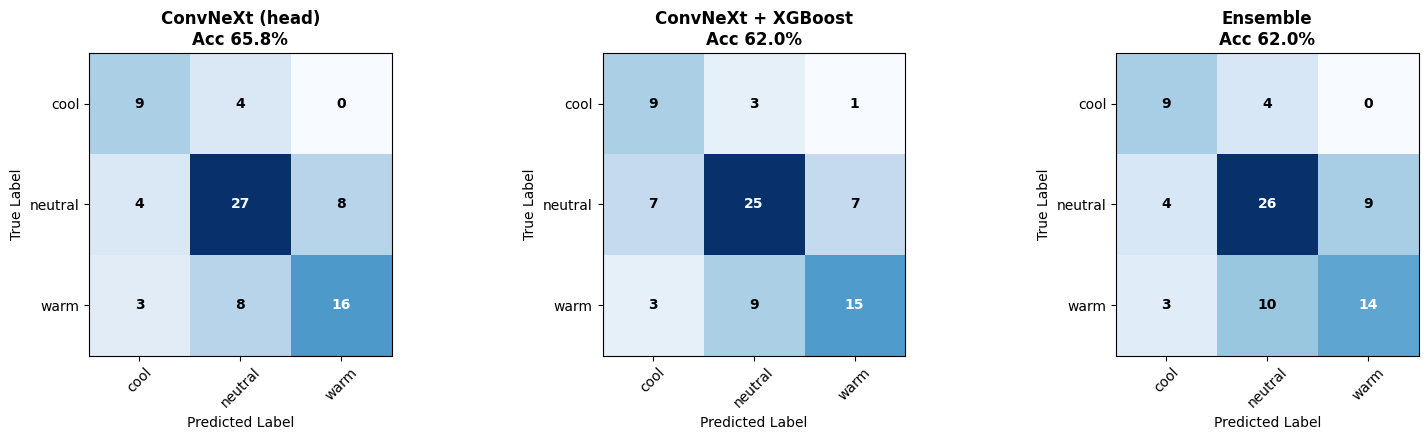

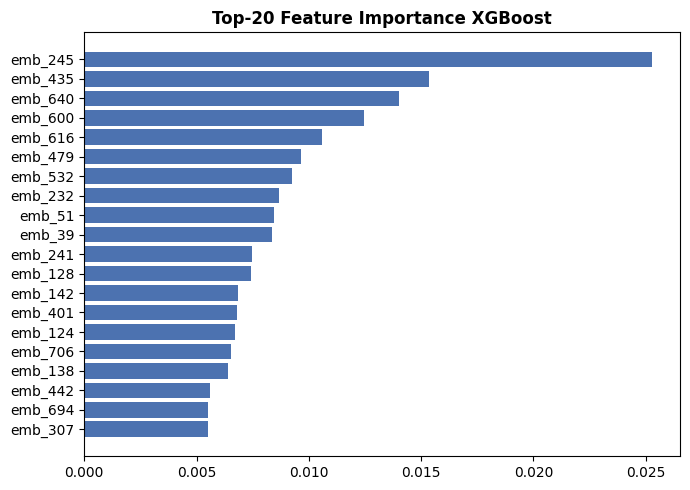

Kontribusi total: embedding ConvNeXt 96.8% | fitur warna 3.2%


In [13]:
# ========================================================
# 13. VISUALISASI HASIL PELATIHAN & CONFUSION MATRIX
# ========================================================
def plot_history(history):
    if not history:
        return
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(epochs, history["train_loss"], "o-", label="Train Loss", color="#1f77b4", linewidth=2)
    axes[0].plot(epochs, history["val_loss"], "s-", label="Val Loss", color="#ff7f0e", linewidth=2)
    axes[0].set_title("ConvNeXt Fine-tuning Loss", fontweight="bold")
    axes[1].plot(epochs, history["train_acc"], "o-", label="Train Acc", color="#2ca02c", linewidth=2)
    axes[1].plot(epochs, history["val_acc"], "s-", label="Val Acc", color="#d62728", linewidth=2)
    axes[1].set_title("ConvNeXt Fine-tuning Accuracy (%)", fontweight="bold")
    for a in axes:
        a.set_xlabel("Epoch"); a.grid(True, linestyle="--", alpha=0.6); a.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "training_curves_convnext.png"), dpi=150)
    plt.show()

def plot_xgb_curve():
    ev = xgb_clf.evals_result()
    plt.figure(figsize=(6.5, 4))
    plt.plot(ev["validation_0"]["mlogloss"], label="Train")
    plt.plot(ev["validation_1"]["mlogloss"], label="Valid")
    plt.axvline(xgb_clf.best_iteration, color="gray", linestyle="--", label="Best iter")
    plt.title("XGBoost mlogloss", fontweight="bold"); plt.xlabel("Boosting round")
    plt.legend(); plt.grid(True, linestyle="--", alpha=0.6); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "xgboost_curve.png"), dpi=150)
    plt.show()

def plot_confusions(results):
    fig, axes = plt.subplots(1, len(results), figsize=(5.2 * len(results), 4.5))
    for ax, (name, res) in zip(np.atleast_1d(axes), results.items()):
        cm = np.array(res["confusion_matrix"])
        ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
        ax.set_title(f"{name}\nAcc {res['accuracy']:.1f}%", fontweight="bold")
        ticks = np.arange(len(CLASS_NAMES))
        ax.set_xticks(ticks); ax.set_xticklabels(CLASS_NAMES, rotation=45)
        ax.set_yticks(ticks); ax.set_yticklabels(CLASS_NAMES)
        thresh = cm.max() / 2.0
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontweight="bold",
                        color="white" if cm[i, j] > thresh else "black")
        ax.set_ylabel("True Label"); ax.set_xlabel("Predicted Label")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_convnext_xgboost.png"), dpi=150)
    plt.show()

def plot_feature_importance(top_k=20):
    imp = xgb_clf.feature_importances_
    emb_dim = X_train.shape[1] - COLOR_FEAT_DIM
    names = [f"emb_{i}" for i in range(emb_dim)] + [f"color_{i}" for i in range(COLOR_FEAT_DIM)]
    order = np.argsort(imp)[::-1][:top_k]
    plt.figure(figsize=(7, 5))
    plt.barh([names[i] for i in order][::-1], imp[order][::-1], color="#4c72b0")
    plt.title(f"Top-{top_k} Feature Importance XGBoost", fontweight="bold")
    plt.tight_layout(); plt.show()
    print(f"Kontribusi total: embedding ConvNeXt {imp[:emb_dim].sum()*100:.1f}% | fitur warna {imp[emb_dim:].sum()*100:.1f}%")

plot_history(history)
plot_xgb_curve()
plot_confusions(results)
plot_feature_importance()

In [14]:
# ========================================================
# 14. INFERENSI SATU GAMBAR (UNTUK DEPLOY)
# ========================================================
def predict_image(path):
    img = load_and_resize(path)
    x, _, p_cn = extract_features([img], np.array([0]))
    p_xgb = xgb_clf.predict_proba(x)
    p = best_w * p_xgb + (1 - best_w) * p_cn
    return {CLASS_NAMES[i]: float(p[0, i]) for i in range(len(CLASS_NAMES))}

if len(test_paths):
    sample = random.choice(test_paths)
    print(os.path.basename(sample), "->", predict_image(sample))

1765001681654_2_jpg.rf.220adddcb6b661506b697e160c5bf35d.jpg -> {'cool': 0.09722759202122688, 'neutral': 0.8689401745796204, 'warm': 0.03383222408592701}


In [15]:
# ========================================================
# 15. REGISTRY LOGGING
# ========================================================
if final_metrics:
    accuracy  = final_metrics["accuracy"]
    f1_score_val = final_metrics["macro_f1"]
    precision = final_metrics["macro_precision"]
    recall    = final_metrics["macro_recall"]

    # auto_log_experiment mencari variabel bernama 'f1' (nama f1_score dipakai fungsi sklearn)
    f1 = f1_score_val

    auto_log_experiment(
        env_globals=globals(),
        topic="topic-b",
        model="ConvNeXt-Tiny + XGBoost",
        objective="Klasifikasi Undertone: fitur ConvNeXt (fine-tuned) + fitur warna Lab/HSV -> XGBoost; augmentasi geometrik & unsharp mask tanpa ubah warna",
        dataset="skin-undertone",
        owner="Egyanta Bareka Sebayang"
    )


===REGISTRY_PAYLOAD_START===
{
  "topic": "topic-b",
  "model": "ConvNeXt-Tiny + XGBoost",
  "objective": "Klasifikasi Undertone: fitur ConvNeXt (fine-tuned) + fitur warna Lab/HSV -> XGBoost; augmentasi geometrik & unsharp mask tanpa ubah warna",
  "dataset": "skin-undertone",
  "owner": "Egyanta Bareka Sebayang",
  "metrics": {
    "accuracy": 62.0253164556962,
    "f1": 60.679824561403514,
    "precision": 60.05112664151565,
    "recall": 62.96296296296296
  }
}
===REGISTRY_PAYLOAD_END===
